**Aim:** Preprocessing scRNA-seq datasets

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)
    - https://scanpy-tutorials.readthedocs.io/en/latest/pbmc3k.html#Preprocessing
        - Identify highly-variable genes
- scAR (single-cell Ambient Remover)
    - https://scar-tutorials.readthedocs.io/en/main/
    - > an explainable machine learning model designed to remove ambient signals from droplet-based single cell omics data. It is suitable for various applications such as sgRNA assignment in scCRISPR-seq, identity barcode assignment in cell multiplexing, protein denoising in CITE-seq, mRNA denoising in scRNAseq, peak count denoising in scATACseq and more.

**Tasks:**
- [X] Identify "dead cells"!
- [x] Data cleaning
    - In the first round of the analysis we have seen that we need to find more dead cells!
    - Run Scrublet with `batch_key='batch'` option. 
    - During my time at Arc Institute I learned more about the QC steps and I aimmed to redo this part and see if we can recover key neuronal cells.
- [X] Remove ambient RNA

___
    round1 Wed Aug 10 17:16:14 PDT 2022
    round2 Fri Mar 31 19:21:57 PDT 2023
    round3 Sun May 19 02:34:26 PDT 2024


In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob
import anndata as ad
import scanpy as sc
import scanpy.external as sce
import scez 
import scar

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

from utils import *

scanpy==1.9.6 anndata==0.10.7 umap==0.5.5 numpy==1.26.4 scipy==1.13.0 pandas==2.1.4 scikit-learn==1.2.2 statsmodels==0.14.2 igraph==0.11.5 pynndescent==0.5.12


In [2]:
# mkdir -pv figures

___


In [3]:
!ls -lh preprocessing/adata-merged*

-rw-rw-r--. 1 aarab aarab 133M May 20  2024 preprocessing/adata-merged-filtered_feature_bc-v3.h5ad.gz
-rw-rw-r--. 1 aarab aarab 971M May 20  2024 preprocessing/adata-merged-raw_feature_bc-v3.h5ad.gz


## Estimate ambient profile
See details in calculating ambient profile



In [ ]:
results_file = 'preprocessing/adata-merged-filtered_feature_bc-v3.h5ad.gz'

adata_filtered_feature_bc = sc.read_h5ad(results_file)

In [77]:
adata_filtered_feature_bc

AnnData object with n_obs × n_vars = 24816 × 32285
    obs: 'batch', 'cond', 'group'
    var: 'gene_ids', 'feature_types', 'genome'

___

In [ ]:
results_file = 'preprocessing/adata-merged-raw_feature_bc-v3.h5ad.gz'

adata_raw_feature_bc = sc.read_h5ad(results_file)

In [78]:
adata_raw_feature_bc

AnnData object with n_obs × n_vars = 13433055 × 32285
    obs: 'batch', 'cond', 'group'
    var: 'gene_ids', 'feature_types', 'genome'

#### 

In [79]:
# adata_filtered_feature_bc.var_names_make_unique()
# adata_raw_feature_bc.var_names_make_unique()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scar/main/_setup.py:99: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  raw_adata.obs["total_counts"] = raw_adata.X.sum(axis=1)


Randomly sample  50000  droplets to calculate the ambient profile.
Estimating ambient profile for  ['Gene Expression']
Categories (1, object): ['Gene Expression'] ...


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scar/main/_setup.py:137: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  raw_adata.obs["log_prob"] = log_prob


iteration:  1
iteration:  2
iteration:  3


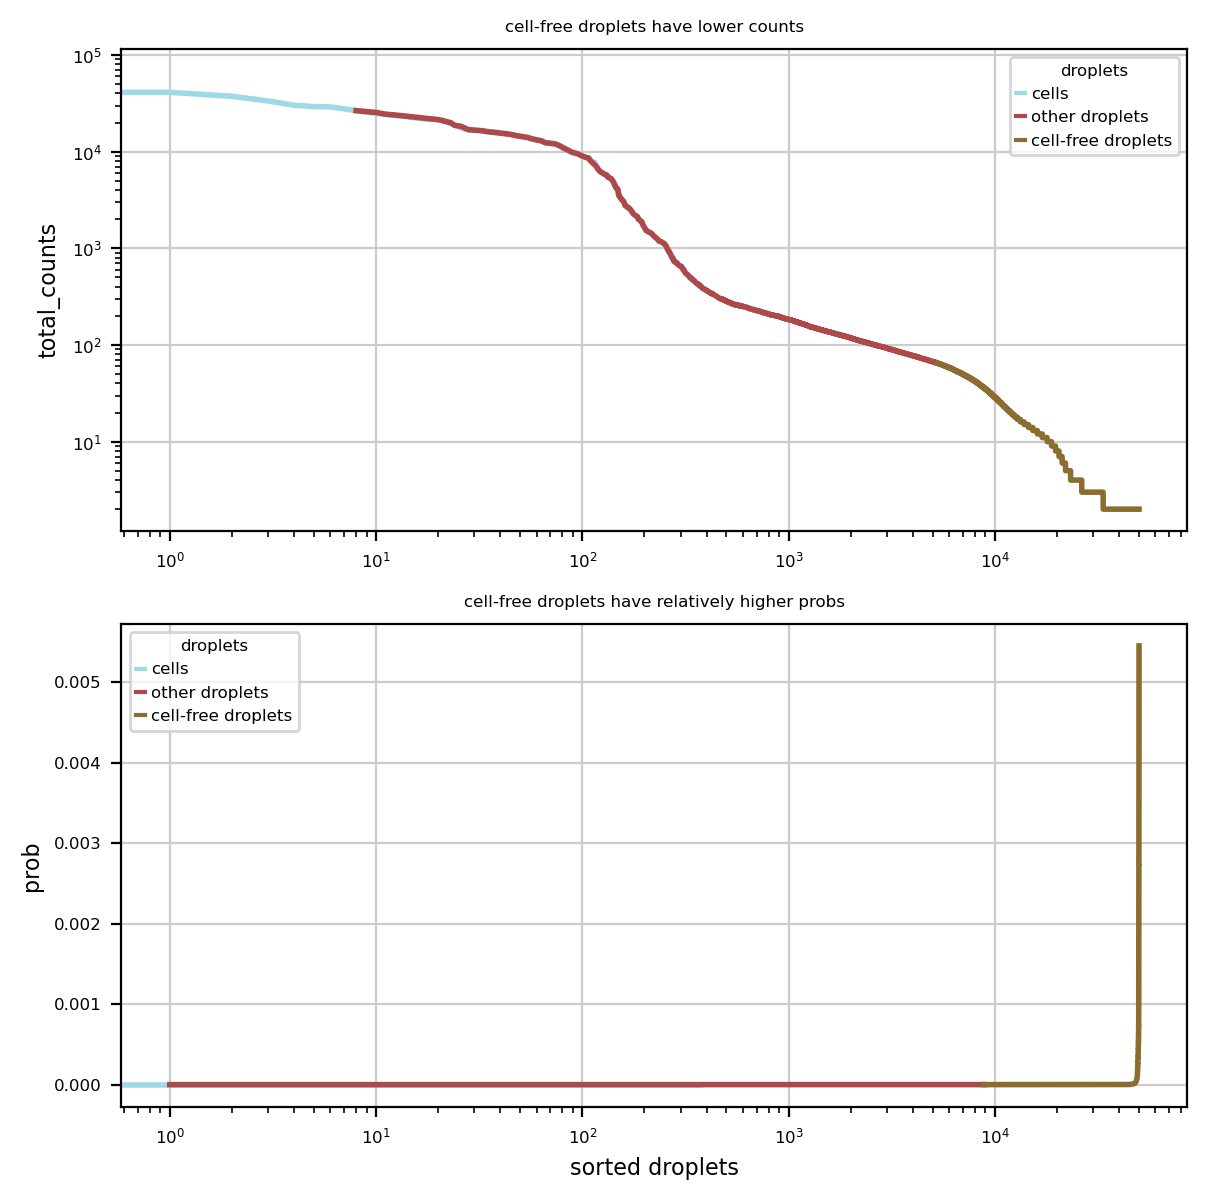

In [80]:
scar.setup_anndata(
    adata = adata_filtered_feature_bc,
    raw_adata = adata_raw_feature_bc,
    prob = 0.995,
    kneeplot = True
)

___

In [94]:
adata_filtered_feature_bc

AnnData object with n_obs × n_vars = 24816 × 32285
    obs: 'batch', 'cond', 'group'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'ambient_profile_Gene Expression'

In [97]:
adata_scar = scar.model(raw_count=adata_filtered_feature_bc.to_df(), # In the case of Anndata object, scar will automatically use the estimated ambient_profile present in adata.uns.
                      # ambient_profile=adata_filtered_feature_bc.uns['ambient_profile_Gene Expression'],
                      feature_type='mRNA',
                      sparsity=1,
                      # device='cpu' # Both cpu and cuda are supported.
                     )

adata_scar.train(epochs=200,
                    batch_size=64,
                    verbose=True
                   )

# After training, we can infer the native true signal
adata_scar.inference(batch_size=256)  # by defaut, batch_size = None, set a batch_size if getting a memory issue

 ... Evaluate empty profile from cells
..Running VAE using the following param set:
......denoised count type:  mRNA
......count model:  binomial
......num_input_feature:  32285
......NN_layer1:  150
......NN_layer2:  100
......latent_space:  15
......dropout_prob:  0
......expected data sparsity:  1
......kld_weight:  1e-05
......lr:  0.001
......lr_step_size:  5
......lr_gamma:  0.97
  Training.....
100%|██████████| 200/200 [1:56:02<00:00, 34.81s/it]
  Inferring .....


In [ ]:
#("preprocessing/scar_model/")

In [101]:
denoised_count = pd.DataFrame(
    adata_scar.native_counts, 
    index=adata_filtered_feature_bc.obs_names, 
    columns=adata_filtered_feature_bc.var_names)

### 

In [194]:
adata = adata_filtered_feature_bc.copy()

In [195]:
adata.layers['raw_counts'] = adata.X
adata.layers['scar_denoised_counts'] = denoised_count.to_numpy()

In [196]:
results_file = 'preprocessing/adata-scar_denoised.h5ad.gz'
adata.write(results_file,compression='gzip')

## Data cleaning

In [4]:
results_file = 'preprocessing/adata-scar_denoised.h5ad.gz'

adata0 = ad.read_h5ad(results_file)

In [5]:
adata = adata0.copy()

___

In [6]:
adata.X = adata.layers["scar_denoised_counts"]

In [13]:
adata

AnnData object with n_obs × n_vars = 24816 × 32285
    obs: 'batch', 'cond', 'group'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'ambient_profile_Gene Expression'
    layers: 'raw_counts', 'scar_denoised_counts'

#### Basic filtering

In [73]:
print(f"Total number of genes: {adata.n_vars}")

sc.pp.filter_cells(adata, min_counts=300)
sc.pp.filter_genes(adata, min_cells=5)
print(f"Number of genes after cell filter: {adata.n_vars}")
print(f"Number of cells after min counts filter: {adata.shape[0]}")

Total number of genes: 32285
Number of genes after cell filter: 12359
Number of cells after min counts filter: 24686


#### Count normalization

In [74]:
scez.pp.normalization(adata, final_layer='log1p_norm', keep_initial_layer=False)

___
#### Filtering cells with high mitochondrial gene counts
- https://www.biostars.org/p/347428/
- https://github.com/theislab/scanpy/issues/639

More Filtering!
- https://nbisweden.github.io/workshop-scRNAseq/labs/compiled/scanpy/scanpy_01_qc.html
> _A standard approach is to filter cells with low amount of reads as well as genes that are present in at least a certain amount of cells. Here we will only consider cells with at least 200 detected genes and genes need to be expressed in at least 3 cells. Please note that those values are highly dependent on the library preparation method used._

~I also found the `total_counts_mt` above a certain threshold useful!~ This is not a good metric for removing dead cells!!

In [75]:
adata.var['mt'] = adata.var.index.str.startswith('mt-') # annotate the group of mitochondrial genes as 'mt'

sc.pp.calculate_qc_metrics(
    adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True, layer = 'log1p_norm'
)

##### plots

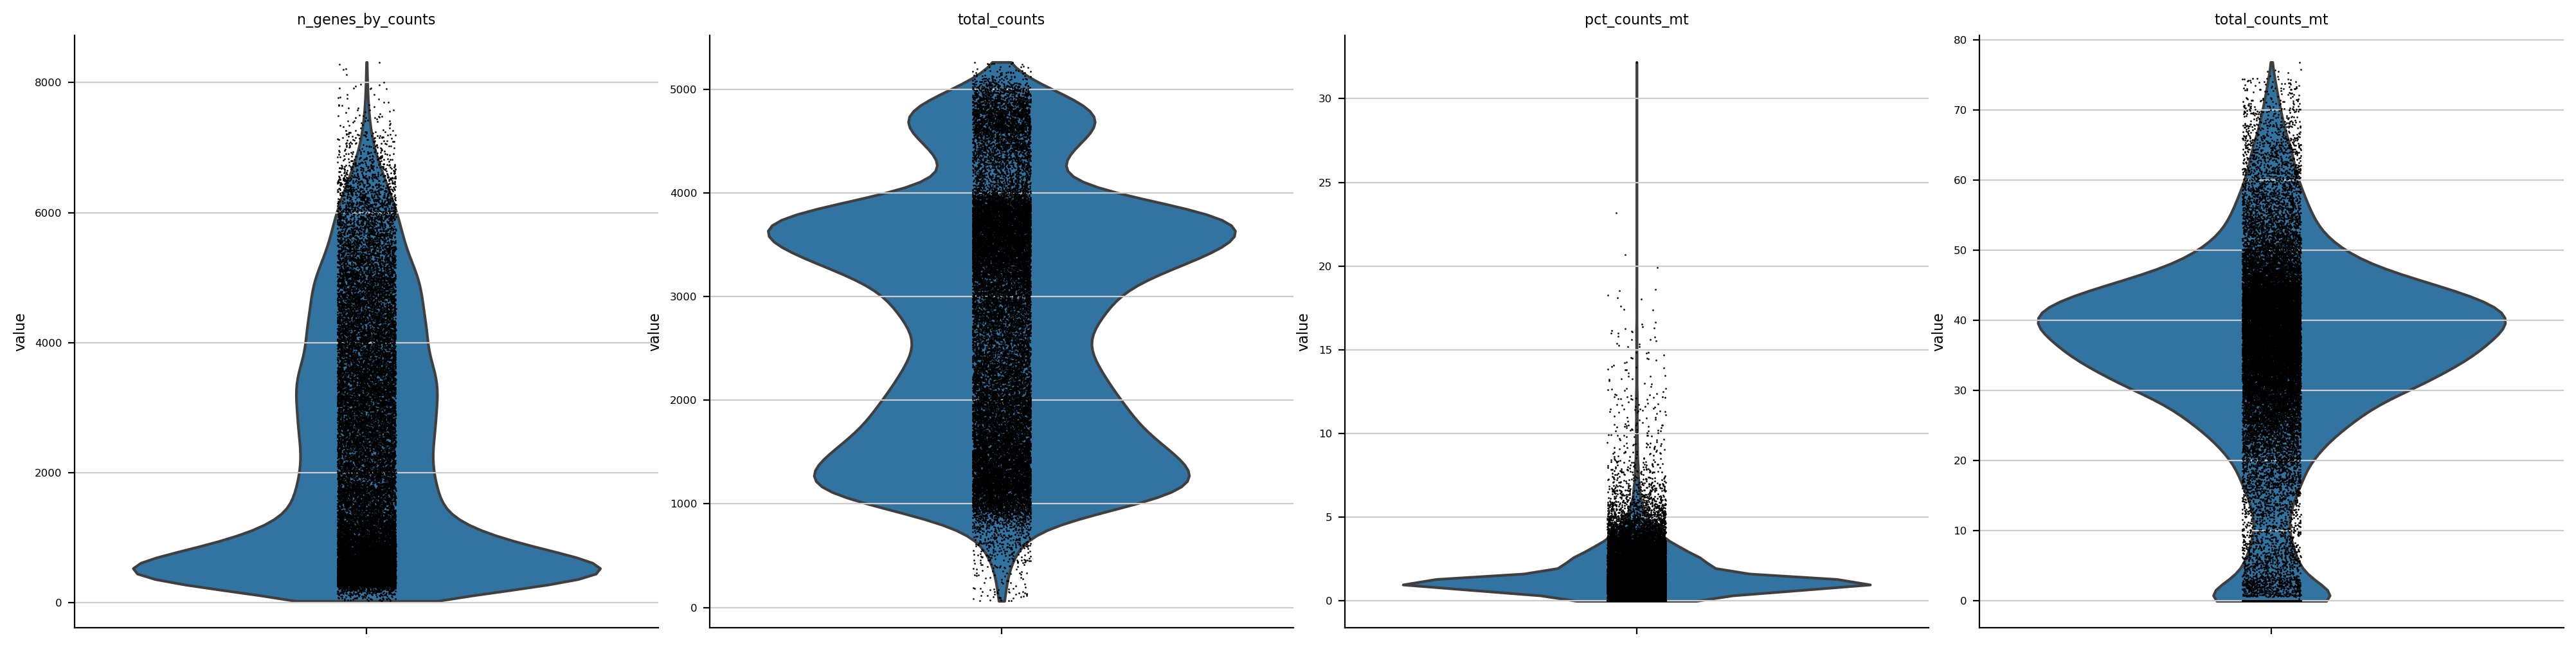

In [76]:
sc.pl.violin(adata, ['n_genes_by_counts', 
                        'total_counts', 
                        'pct_counts_mt',
                        'total_counts_mt'],
             jitter=0.05, multi_panel=True)

In [77]:
# pdf_pages = PdfPages(f'preprocessing/violin_mitochondrial_all.pdf')
# for col in [
#     # 'n_genes_by_counts','total_counts',
#     'pct_counts_mt','total_counts_mt'
# ]:
#     # Create a figure instance (ie. a new page)
#     fig = plt.figure(figsize=(12, 6), dpi=300)
#     # Plot whatever you wish to plot
#     print ('\033[1m' + col)
#     ax = plt.subplot()
#     sc.pl.violin(
#         adata_qc, col, jitter=0.05, groupby='batch', 
#         multi_panel=True, ax=ax,rotation=90
#     )
#     # Done with the page
#     pdf_pages.savefig(fig,bbox_inches='tight')
# # Write the PDF document to the disk
# pdf_pages.close()

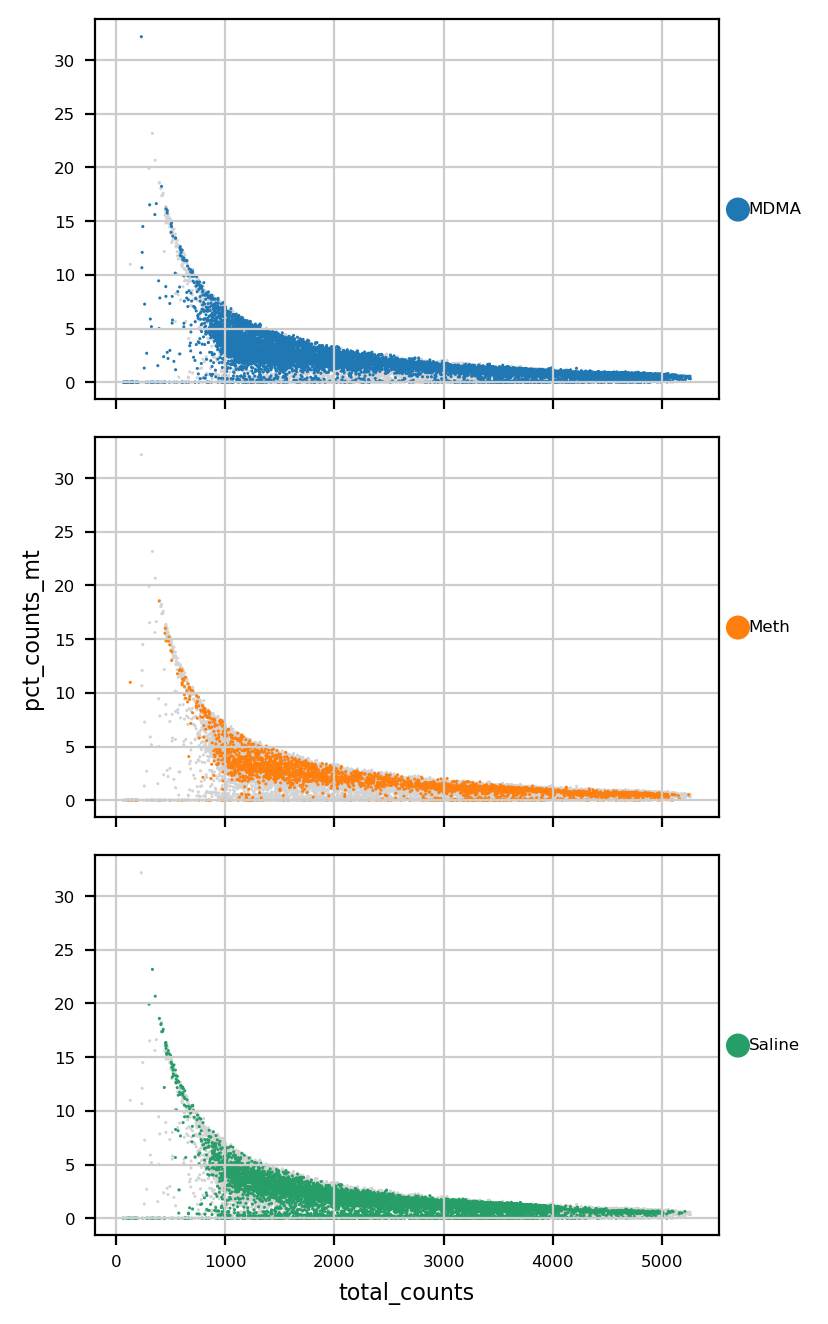

In [78]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(4,8), gridspec_kw={'hspace':0.1}, sharex='all')

ax1_dict = sc.pl.scatter(
    adata, x='total_counts', color='group', y='pct_counts_mt',ax=ax1, show=False,#alpha=0.1,
    groups=['MDMA']
)
ax1.set_title('')
# ax1.set_xscale('log')
ax1.set_xlabel('')
ax1.set_ylabel('')


ax2_dict = sc.pl.scatter(
    adata, x='total_counts', color='group', y='pct_counts_mt',ax=ax2, show=False,#alpha=0.1,
    groups=['Meth']
    
)
ax2.set_title('')
# ax2.set_xscale('log')
ax2.set_xlabel('')

ax3_dict = sc.pl.scatter(
    adata, x='total_counts', color='group', y='pct_counts_mt',ax=ax3, show=False,#alpha=0.1,
    groups=['Saline']
    
)
ax3.set_title('')
# ax3.set_xscale('log')
ax3.set_ylabel('')
# plt.savefig('preprocessing/scatter_total_counts_mt_vs_total_counts.pdf')
plt.show()

#### Remove cells with high mt- expression
- [x] high `pct_counts_mt`
- [ ] ~high total counts `mt`~

In [96]:
adata1 = adata.copy()

In [98]:
thr_pct_mt = 5

In [99]:
# # filter based on MT counts % 

# filter_stat_df = pd.concat([
#     adata_qc.obs.groupby('batch').size(),
#     adata_qc[adata_qc.obs.pct_counts_mt > thr_pct_mt].obs.groupby('batch').size(),
#     # adata_qc[adata_qc.obs.total_counts_mt > thr_cnt_mt].obs.groupby('batch').size(),
#     adata_qc[
#         (adata_qc.obs.pct_counts_mt > thr_pct_mt) 
#         # |
#         # (adata_qc.obs.total_counts_mt > thr_cnt_mt)
#     ].obs.groupby('batch').size(),
# ],axis=1).rename(columns={
#     0:'total number of cells',
#     1:f'pct_counts_mt > {thr_pct_mt}',
#     # 2:f'total_counts_mt > {thr_cnt_mt}',
#     # 3:f'pct_counts_mt > {thr_pct_mt} OR total_counts_mt > {thr_cnt_mt}'
# })

# filter_stat_df

In [100]:
# filter_stat_df.sum()

Actual filtering!

In [101]:
adata1

AnnData object with n_obs × n_vars = 24686 × 12359
    obs: 'batch', 'cond', 'group', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'ambient_profile_Gene Expression', 'group_colors'
    layers: 'raw_counts', 'scar_denoised_counts', 'log1p_norm', 'scaled'

In [102]:
print(f"Number of cells with high `pct_counts_mt`: {sum(adata1.obs.pct_counts_mt > thr_pct_mt)}")

adata1 = adata1[~
    ((adata1.obs.pct_counts_mt > thr_pct_mt))
].copy()

print(f"Number of cells after dead-cell filter: {adata1.shape[0]}")

Number of cells with high `pct_counts_mt`: 916
Number of cells after dead-cell filter: 23770


In [110]:
adata.obs[adata.obs.pct_counts_mt >= thr_pct_mt].groupby('batch').size()

batch
MDMA_acute_female_1     10
MDMA_acute_female_2     11
MDMA_acute_female_3     16
MDMA_acute_male_1      229
MDMA_acute_male_2      123
MDMA_acute_male_3       69
MDMA_male_1              9
MDMA_male_2             14
MDMA_male_3             32
Meth_male_1             89
Meth_male_2             49
Meth_male_3             24
Saline_male_1           14
Saline_male_2           64
Saline_male_3          163
dtype: int64

#### Remove doublet

- https://github.com/swolock/scrublet/blob/master/examples/scrublet_basics.ipynb

<!-- > #### Plot doublet score histograms for observed transcriptomes and simulated doublets
The simulated doublet histogram is typically bimodal. The left mode corresponds to "embedded" doublets generated by two cells with similar gene expression. The right mode corresponds to "neotypic" doublets, which are generated by cells with distinct gene expression (e.g., different cell types) and are expected to introduce more artifacts in downstream analyses. Scrublet can only detect neotypic doublets.

> To call doublets vs. singlets, we must set a threshold doublet score, ideally at the minimum between the two modes of the simulated doublet histogram. `scrub_doublets()` attempts to identify this point automatically and has done a good job in this example. However, if automatic threshold detection doesn't work well, you can adjust the threshold with the `call_doublets()` function. For example: -->

In [111]:
# adata_scr = adata.copy()

In [112]:
# sce.pp.scrublet(adata,batch_key='batch')

In [113]:
# scr_thr = []
# for k in adata_scr.uns['scrublet']['batches']:
#     scr_thr.append((k,adata_scr.uns['scrublet']['batches'][k]['threshold']))

In [114]:
# adata_scr.obs.groupby(['group','predicted_doublet']).size()

In [115]:
# results_file = 'preprocessing/adata-scr.h5ad.gz'
# adata_scr.write(results_file,compression='gzip')

In [116]:
# !ls -s --block-size=M $results_file
# !rm -rv preprocessing/adata-scr*

In [117]:
# adata1

#### filter doublet


In [118]:
# # remove doublet
# doublet_cells = set(adata_scr.obs.index[adata_scr.obs.predicted_doublet])
# print(
#     f'from {len(doublet_cells)} doublets only {len(doublet_cells & set(adata1.obs.index))} cells are not filtered already!'
# )

Actual filtering!

In [119]:
# adata1 = adata1[~adata1.obs.index.isin(list(doublet_cells & set(adata1.obs.index)))]

### Explore data!

#### Prepare for UMAP

In [170]:
adata2 = adata1.copy()

In [171]:
# Randomly order cells by making a random index and subsetting AnnData based on it
# Set a random seed to ensure that the cell ordering will be reproducible
np.random.seed(0)
random_indices = np.random.permutation(list(range(adata2.shape[0])))

#### Regress out for `total_counts`
- https://github.com/theislab/single-cell-tutorial/issues/35
- https://github.com/scverse/scanpy/issues/526#issuecomment-471488594

In [172]:
# sc.pp.regress_out(adata2, ['total_counts'])

___

In [173]:
sc.pp.highly_variable_genes(
    adata2, min_mean=0.01, max_mean=10, min_disp=0.01,
)

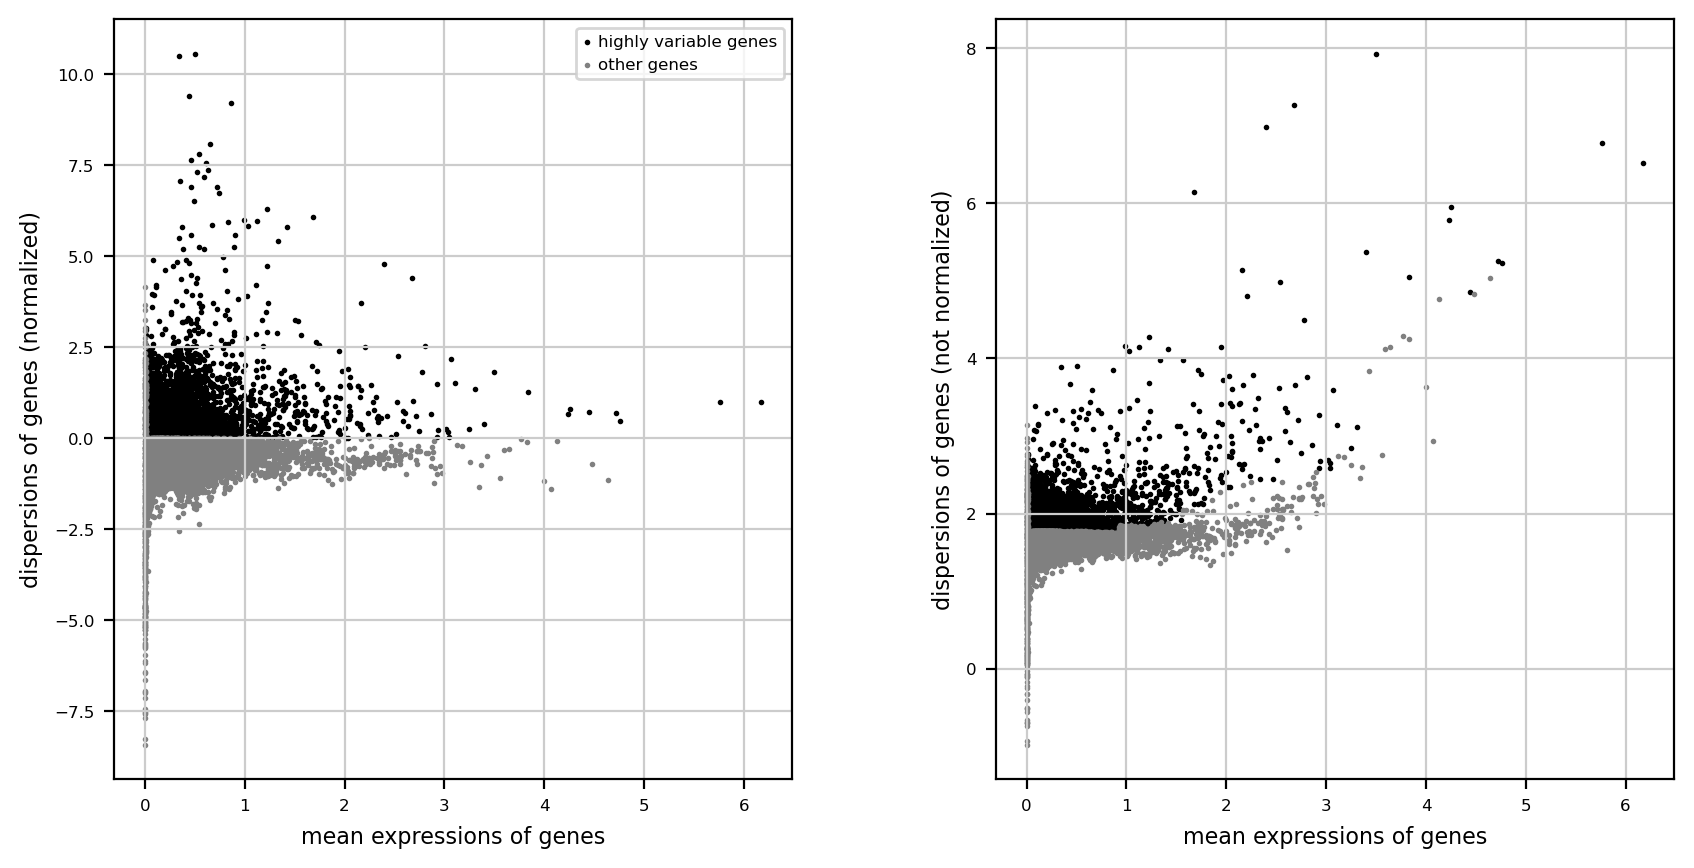

In [174]:
sc.pl.highly_variable_genes(adata2) # scanpy generates the filename automatically

In [175]:
adata2.var.highly_variable.sum()

5699

In [176]:
sc.pp.pca(adata2,n_comps=30,use_highly_variable=True, svd_solver='arpack')
sc.pp.neighbors(adata2)    # why can't we just work with the default neighbors?
#, use_rep=rep, n_neighbors=n_neighbor)

In [179]:
# neighbors were already computed using scVI
sc.tl.leiden(adata2, key_added="leiden_cleaned", resolution=.5)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/umap/umap_.py:1393: RuntimeWarning: divide by zero encountered in power
  return 1.0 / (1.0 + a * x ** (2 * b))
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting

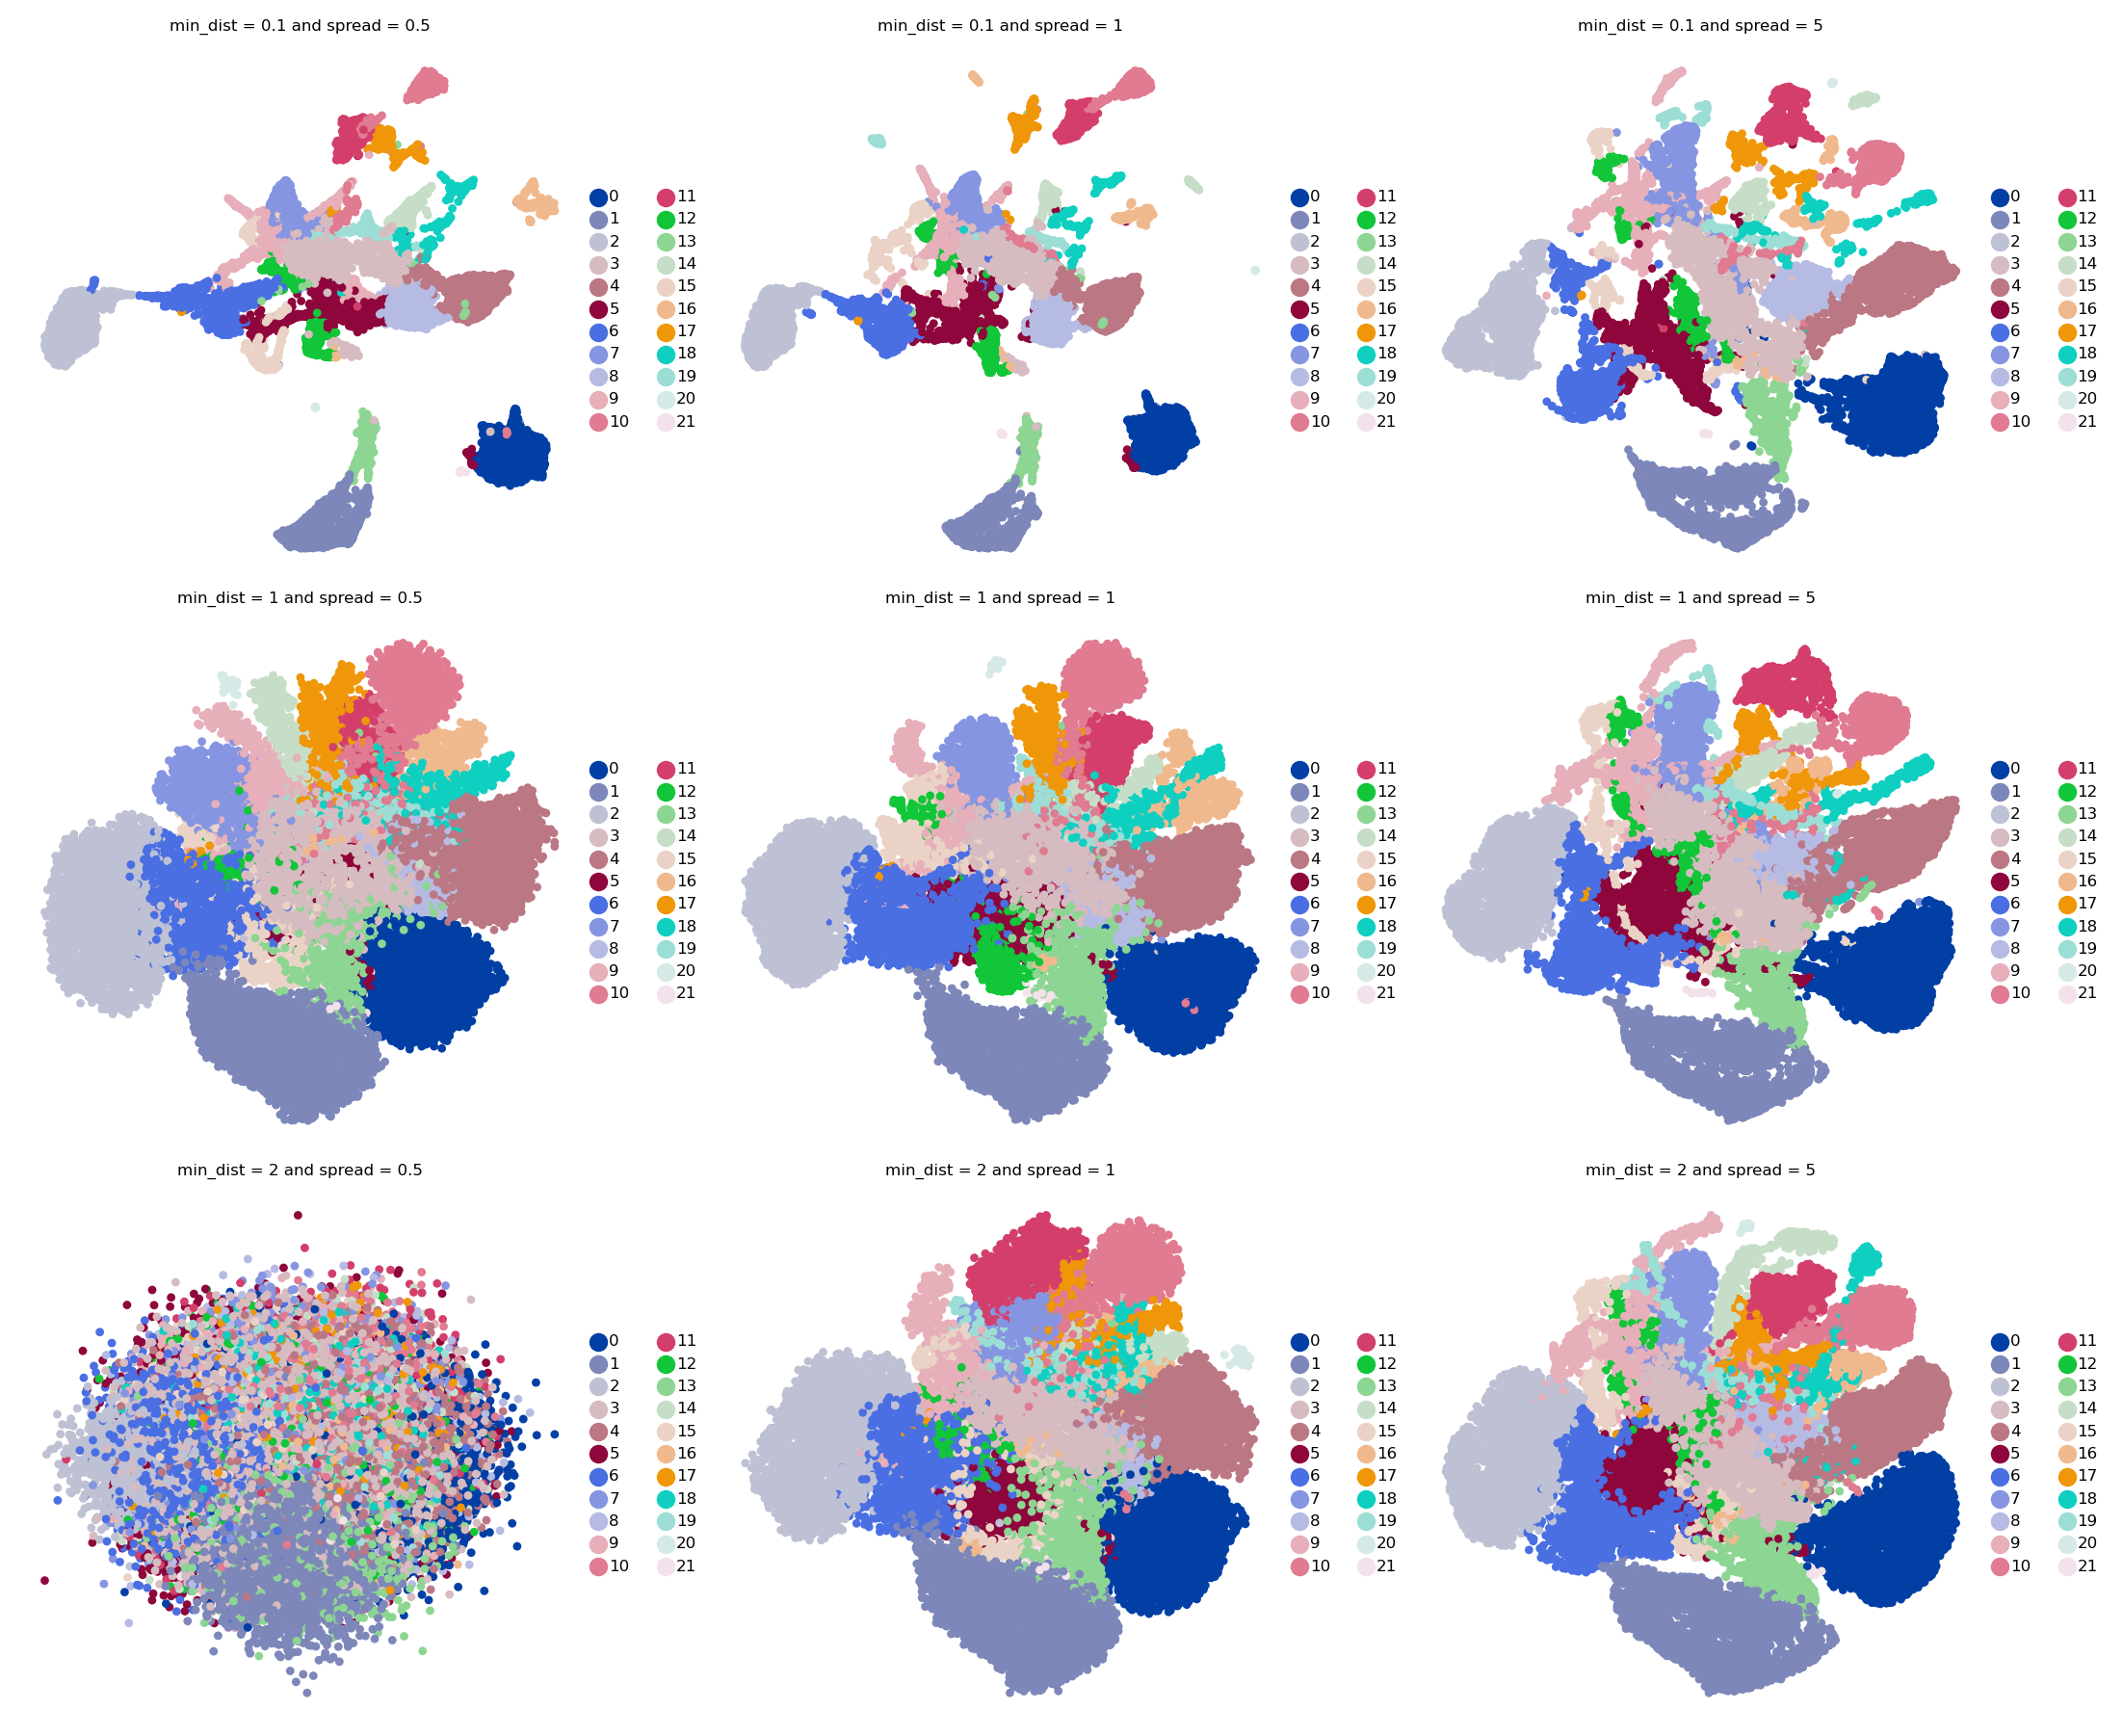

In [180]:
scez.rp.optimising_umap_layout(adata2,'leiden_cleaned')

In [181]:
sc.tl.umap(adata2, min_dist=1, spread=.5)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:381: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/p

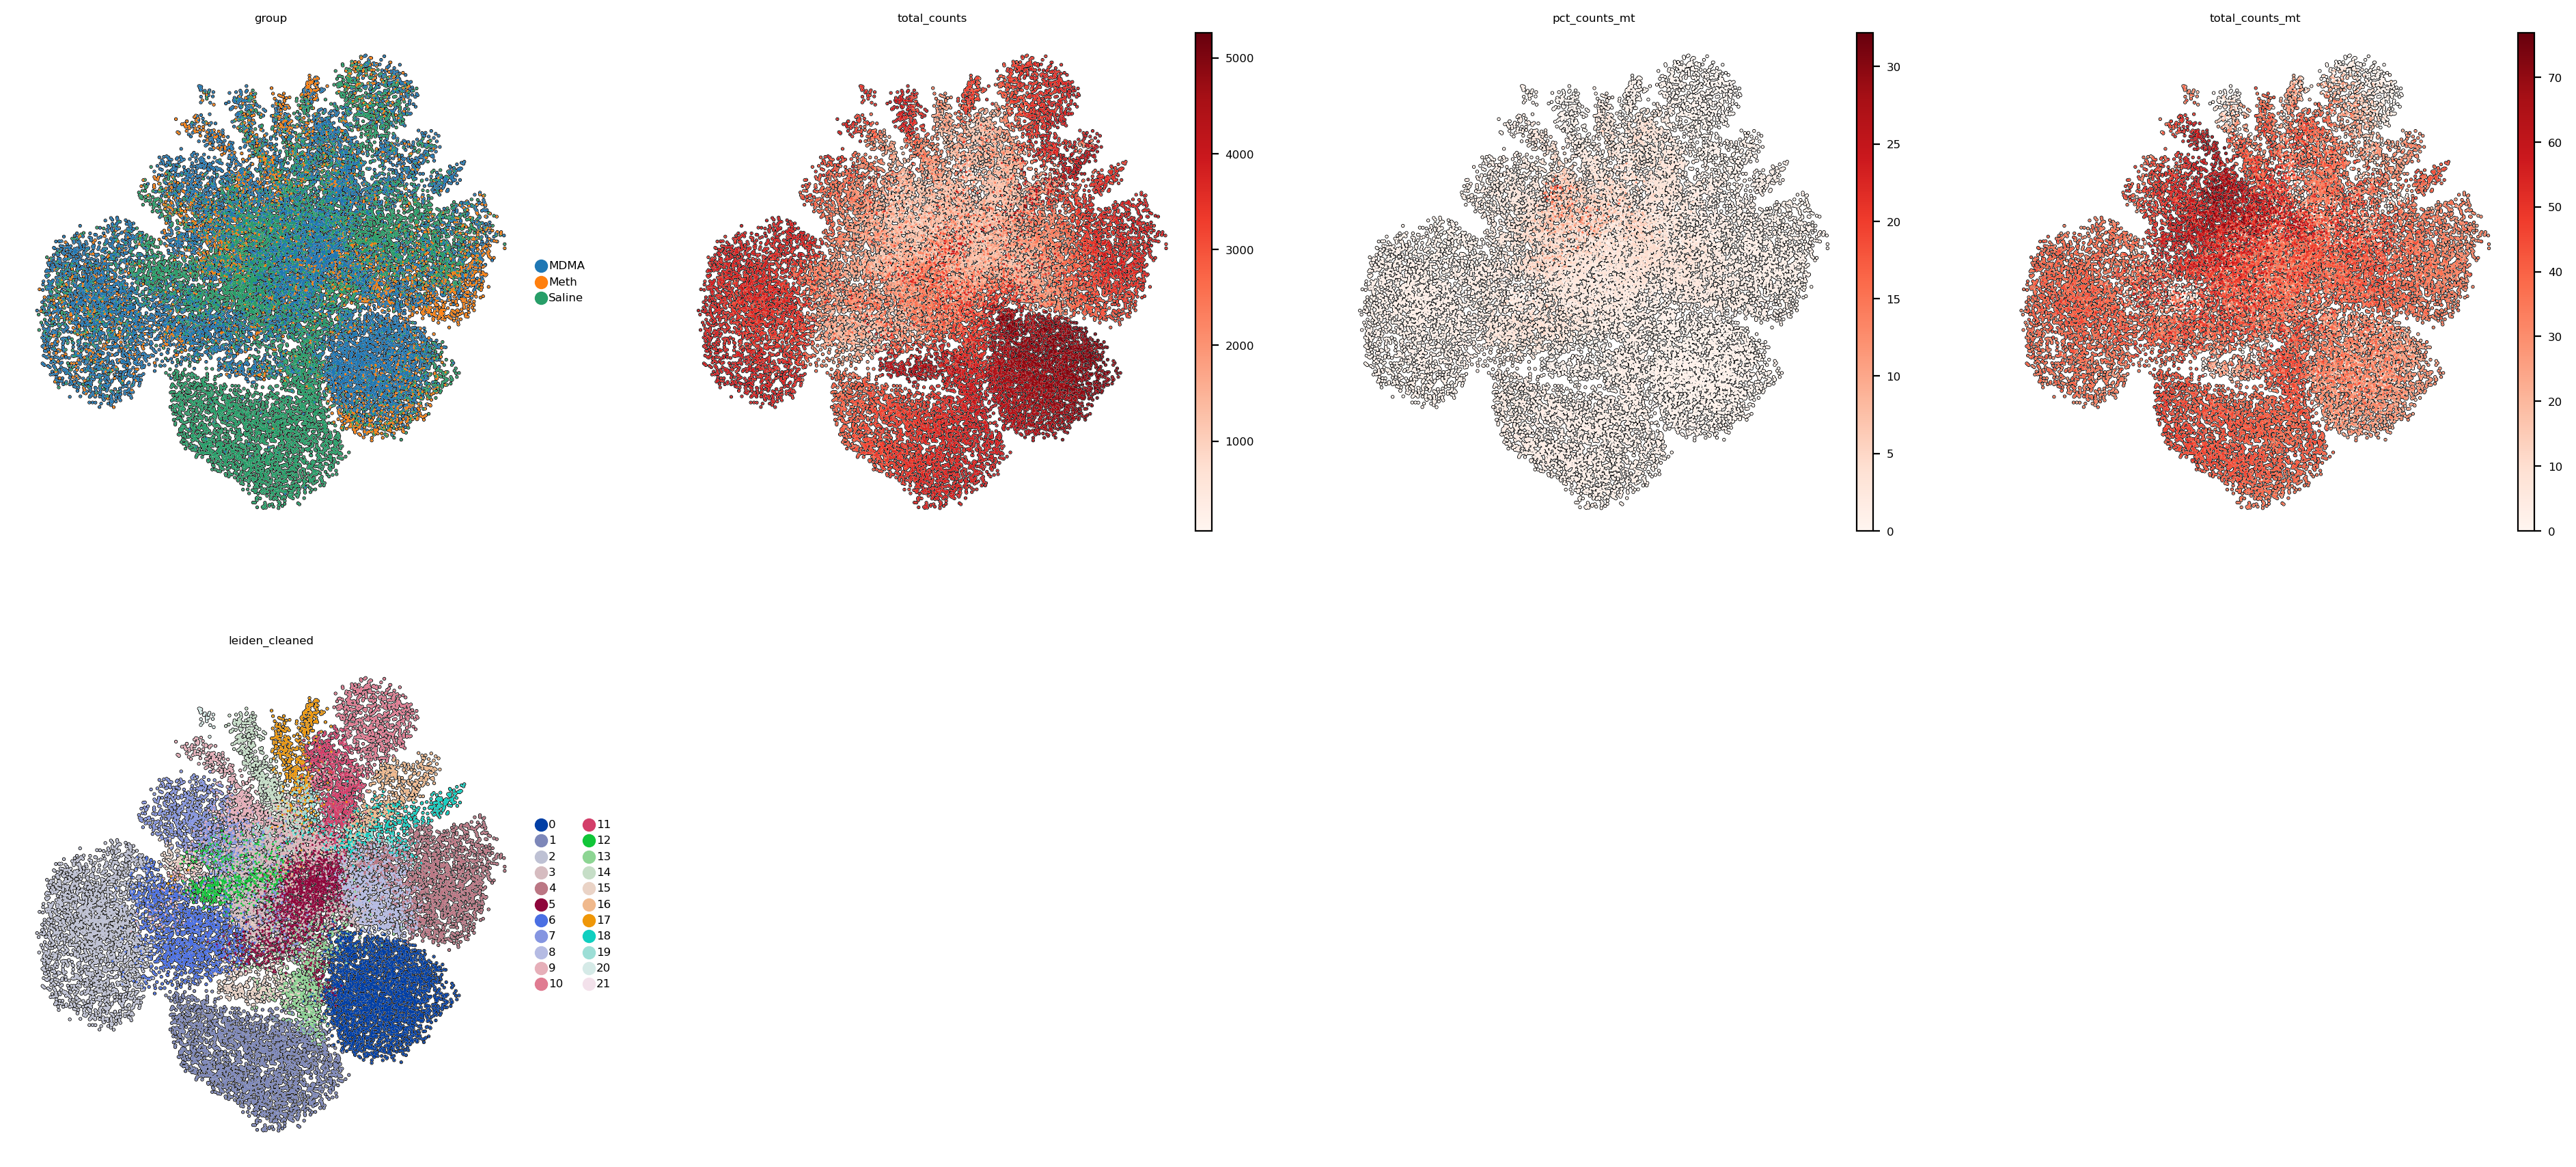

In [182]:
sc.pl.umap(
    adata2[random_indices],
    color=['group','total_counts','pct_counts_mt','total_counts_mt', 'leiden_cleaned'],
    layer='scaled',
    cmap='Reds',
    frameon=False,
    alpha=1,
    size=5,
    add_outline=0.01
    # vmin=5,# vmax=1000,
    # save='all.pdf',
    # add_outline=.1
)

# !mv figures/umapall.pdf preprocessing/total_counts_mt_umap.pdf

### Save pre-processed data 

In [183]:
results_file = 'preprocessing/adata-cleaned.h5ad.gz'

adata2.write(results_file,compression='gzip')

#### save top genes per cluster

In [262]:
sc.tl.rank_genes_groups(
    adata2, 'leiden_cleaned', method='wilcoxon'
)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:396: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'names'] = self.var_names[global_indices]
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:398: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'scores'] = scores[global_indices]
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/s

In [265]:
ranked_clusters_full = scez.utils.rank_genes_to_df(
    adata2,
    n = 200
    # n = adata_neuron.var.shape[0]
)

In [269]:
ranked_clusters_full.to_csv('preprocessing/ranked_clusters_full.csv')

#### save small data for browser view
https://www.kanaverse.org/kana/

In [251]:
adata2_small = adata2.copy()

adata2_small = adata2_small[:,adata2_small.var.highly_variable].copy()

adata2_small.var = adata2_small.var.reset_index().rename(
    columns={'index':'gene_names'}).set_index('gene_ids')

In [253]:
del adata2_small.layers

del adata2_small.uns['ambient_profile_Gene Expression']
del adata2_small.uns['group_colors']

for col in ["n_counts","n_genes_by_counts","total_counts","total_counts_mt","pct_counts_mt"]:
    del adata2_small.obs[col]

for col in adata2_small.var.columns:
    if col not in ["gene_names","total_counts",'highly_variable']:
        del adata2_small.var[col]

In [254]:
results_file = 'preprocessing/adata-cleaned.small.h5ad'

adata2_small.write(results_file)

In [255]:
!ls -s --block-size=M preprocessing/adata-cleaned*

 812M preprocessing/adata-cleaned.h5ad.gz
1295M preprocessing/adata-cleaned.small.h5ad


# 
<!-- Wed Apr 27 15:50:17 PDT 2022 -->

In [248]:
%reload_ext watermark
%watermark
%watermark --iversions

Last updated: 2024-05-20T16:46:26.097508-07:00

Python implementation: CPython
Python version       : 3.9.19
IPython version      : 8.18.1

Compiler    : GCC 12.3.0
OS          : Linux
Release     : 3.10.0-957.27.2.el7.x86_64
Machine     : x86_64
Processor   : x86_64
CPU cores   : 64
Architecture: 64bit

scanpy    : 1.9.6
anndata   : 0.10.7
numpy     : 1.26.4
matplotlib: 3.6.3
scez      : 0.0.6
scar      : 0.4.3
seaborn   : 0.12.2
pandas    : 1.5.3
sys       : 3.9.19 | packaged by conda-forge | (main, Mar 20 2024, 12:50:21) 
[GCC 12.3.0]



In [169]:
!date

Mon May 20 15:00:29 PDT 2024
